# 07 Évaluation finale de la segmentation

Deux versions, figées avant d'ouvrir le test, dont les résultats sont publiés tels quels :
- **version 1** : le U-Net seul (`unet_effb0_tout`, encodeur EfficientNet-B0, entraîné sur tout le train 150 DPI, notebook 05) ;
- **version 1.1** : le même U-Net suivi du **classifieur des taches** (notebook E4), qui retire les taches prédites jugées fausses ; entraîné et réglé sur le val de PRMI, il découvre le test ici.

Trois jeux de test, tous jamais vus pendant le développement (tubes absents du train et du val) :

| Jeu | Images | Référence |
|---|---|---|
| **Test corrigé** | 50, tirées au hasard dans le test 150 DPI | masques corrigés à la main, sans voir de prédiction : la référence la plus fiable |
| **Grand test 150 DPI** | 4 743 (12 tubes) | annotation PRMI (rectangles), fentes comblées |
| **Test 120 DPI** | 3 542 (7 tubes, autre caméra, autre site, autre année) | annotation PRMI, fentes comblées : test de généralisation à un autre capteur |

Les masques prédits sont enregistrés (`data/processed/predictions/unet_effb0_tout/`) pour mesurer ensuite longueurs et diamètres sans refaire les prédictions.

In [2]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
import pandas as pd

from prmi import blob_classifier as bc, gaps, viz
from prmi.dataset import load_lot, test_rows
from prmi.train import (PRED_DIR, RUNS_DIR, key_scores, largest_blobs, load_run, postprocess_study, predict,
                        prediction_loader, predict_items, predict_rows, summarize, timing, trait_scores, traits)

viz.apply_style()
pd.set_option('display.width', 180)
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 90

NAME = 'unet_effb0_tout'                   # version 1
SCALE = 2

## 1. Prédictions

Calculées une fois, puis relues (clé branchée) : environ 50 min pour le U-Net seul, puis autant pour la version 1.1, qui a besoin des cartes de probabilité. Le 120 DPI est réduit de moitié comme le 150 DPI : sur les masques du train, ses racines ont en pixels une largeur proche de celles du 150 DPI.

In [3]:
model = load_run(NAME)[0]
device = next(model.parameters()).device
test_items = load_lot('test', SCALE)                       # 50 images, masques corrigés

file = RUNS_DIR / NAME / 'test_images.csv'
if file.exists():
    test = pd.read_csv(file)
else:
    test = predict_items(model, test_items, device, PRED_DIR / NAME / 'test_corrige')
    test.to_csv(file, index=False)

rows150, rows120 = test_rows(150), test_rows(120)
for rows in (rows150, rows120):
    gaps.save_filled(rows)                                 # fentes de l'annotation PRMI comblées (déjà fait : rien)
tables = {'test corrigé': test,
          'grand test 150 DPI': predict_rows(NAME, rows150, 'test_150'),
          'test 120 DPI': predict_rows(NAME, rows120, 'test_120')}

In [4]:
clf, TAU = bc.load(RUNS_DIR / NAME / 'classifieur_taches.joblib')       # notebook E4
OPTIONS = bc.v11_options(clf, TAU)
runs = {'test corrigé': postprocess_study(NAME, 'test_corrige_v11', OPTIONS, items=test_items),
        'grand test 150 DPI': postprocess_study(NAME, 'test_150_v11', OPTIONS, rows=rows150),
        'test 120 DPI': postprocess_study(NAME, 'test_120_v11', OPTIONS, rows=rows120)}
v11 = {k: r[r['variante'] == 'U-Net + classifieur'] for k, r in runs.items()}

## 2. Résultats (version 1.1)

,images,avec racine,Dice médian,Dice global,clDice médian,erreur de longueur médiane,racines trouvées,images vides touchées
test corrigé,50.0,32.0,0.79,0.77,0.84,0.20,0.80,0.00
grand test 150 DPI,4743.0,2765.0,0.74,0.73,0.85,0.21,0.67,0.13
test 120 DPI,3542.0,1683.0,0.79,0.75,0.88,0.25,0.85,0.20


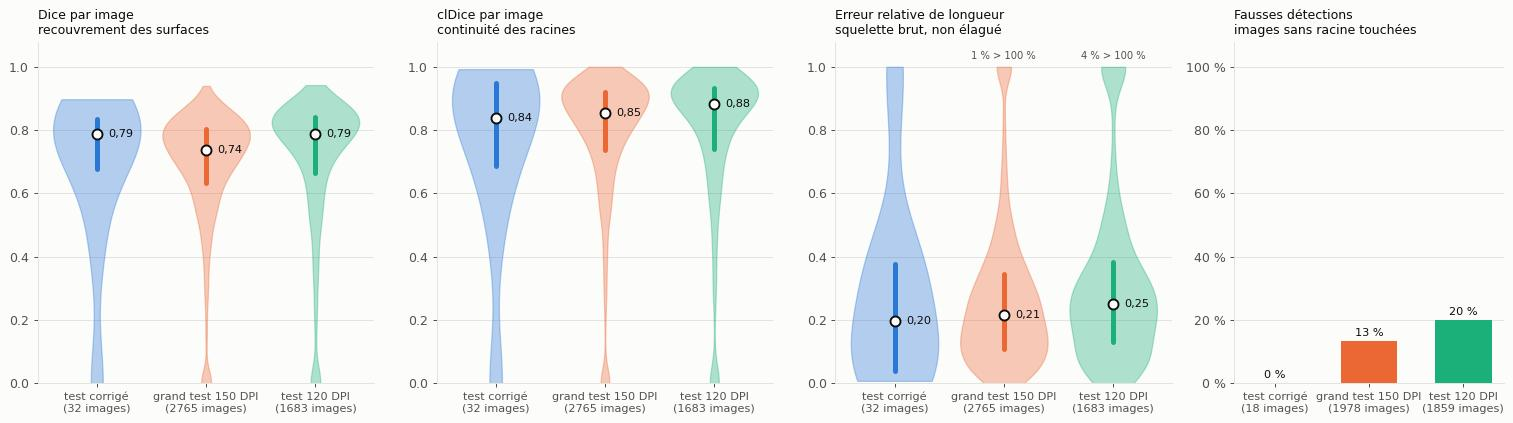

In [5]:
fig = viz.plot_test_results(v11)
viz.save(fig, 'test_resultats.png')
pd.DataFrame({k: key_scores(t) for k, t in v11.items()}).T.round(2)

Avec et sans le classifieur des taches, sur les trois jeux de test :

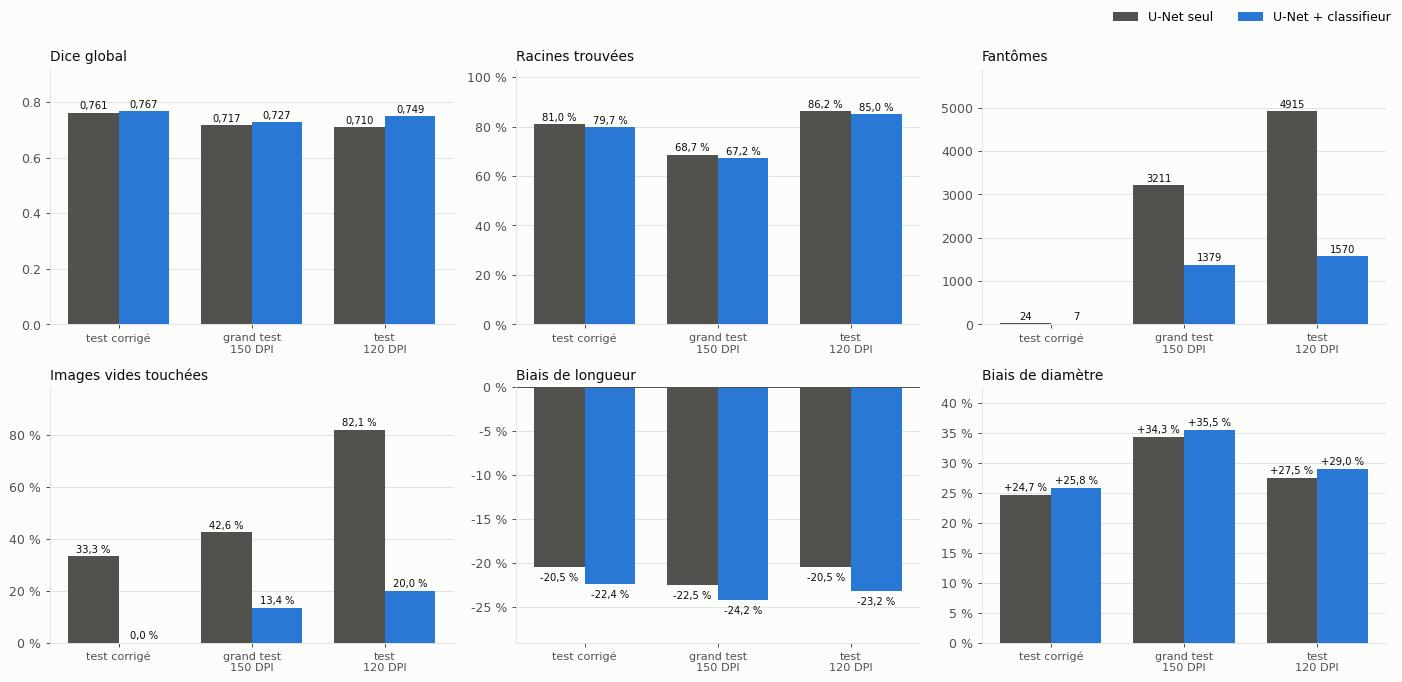

In [6]:
METRICS = ['global_dice', 'roots_found', 'ghosts', 'fp_empty', "longueur : biais d'ensemble", "diamètre : biais d'ensemble"]
compare = {k: pd.DataFrame({v: {**summarize(g), **trait_scores(g)} for v, g in r.groupby('variante', sort=False)}).T[METRICS]
           for k, r in runs.items()}
viz.save(viz.plot_compare_sets(compare, METRICS), 'test_avec_sans_classifieur.png')

**À retenir**
- **Segmentation solide et stable** : Dice médian de 0,74 à 0,79 par image et clDice médian de 0,84 à 0,88 sur les trois jeux, y compris sur l'autre capteur (120 DPI), jamais vu à l'entraînement.
- **Le classifieur des taches tient ses promesses sur le test** : images sans racine touchées 33 % → 0 % (test corrigé, 18 images vides), 43 % → 13 % (grand test 150 DPI) et 82 % → 20 % (120 DPI) ; fantômes divisés par 2,3 à 3,4 ; Dice global en hausse sur les trois jeux (+0,006, +0,010, +0,039). Le gain le plus fort est sur l'autre capteur, où les fausses détections étaient le principal défaut.
- **Coût limité** : 1,2 à 1,5 point de racines trouvées en moins ; biais de longueur un peu plus fort (-20 à -23 % → -22 à -24 %) ; diamètre presque inchangé (+1 point).
- **Reste à fiabiliser la mesure** : longueur sous-estimée d'environ 22 %, diamètre surestimé de 26 à 36 %. C'est l'objet de l'étape suivante (élagage des squelettes, reconnexion des racines en pointillés, mesures en millimètres).


## 3. Où se trompe le U-Net

Les sections 3 à 8 analysent les erreurs du U-Net seul (version 1), avant le classifieur.


Score par image selon la quantité de racine dans l'image : les erreurs se concentrent sur les images qui ne contiennent que quelques fragments de racine.

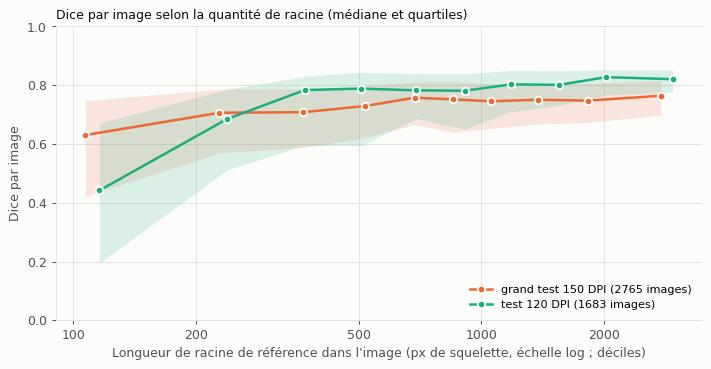

In [7]:
viz.save(viz.plot_by_amount({k: t for k, t in tables.items() if k != 'test corrigé'}, viz.TEST_COLORS[1:]),
         'test_dice_selon_quantite.png')

## 4. Fausses détections sur les images sans racine

Pour chaque image sans racine, taille de la plus grosse tache prédite. La courbe donne la part des images vides qui gardent une tache d'au moins cette taille : c'est ce qu'un filtre des petites taches après la prédiction laisserait passer. C'est le problème que corrige le classifieur des taches (section 2).

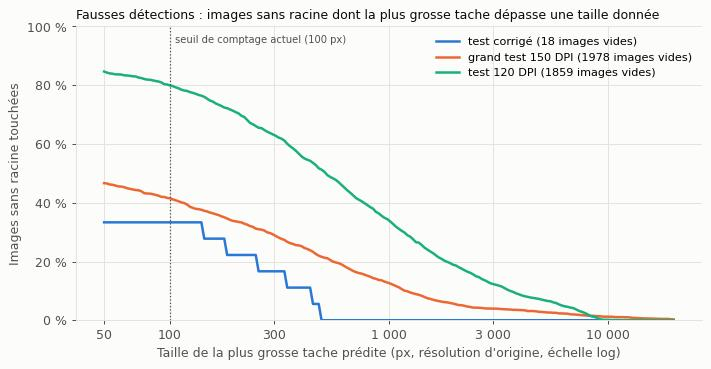

In [8]:
LOTS = {'test corrigé': 'test_corrige', 'grand test 150 DPI': 'test_150', 'test 120 DPI': 'test_120'}
blobs = {k: largest_blobs(t, PRED_DIR / NAME / LOTS[k]) for k, t in tables.items()}
viz.save(viz.plot_false_detections(blobs), 'test_fausses_detections.png')

**À retenir**
- **150 DPI : surtout de petites taches.** 42 % des images vides ont une tache d'au moins 100 px, mais 13 % seulement d'au moins 1 000 px (une image fait environ 400 000 px). Le classifieur des taches (section 2) les retire en grande partie.
- **120 DPI : des taches plus grosses** (34 % des images vides au-delà de 1 000 px) : l'effet du changement de capteur, et peut-être de racines non annotées (bord gauche sous-annoté, notebook 01). Le classifieur, qui tient compte du contexte de l'image, fait pourtant passer les images vides touchées de 82 % à 20 %.

## 5. Longueurs et diamètres : premier aperçu

Pour chaque image avec racine, sur la prédiction et sur la référence : **longueur** = nombre de pixels du squelette, **diamètre moyen** = surface / longueur. Unités : pixels à la résolution d'origine (le DPI annoncé reste à vérifier avant de passer aux millimètres). Squelettes bruts, sans élagage des petites branches, des deux côtés. La référence du test corrigé est la plus fiable ; celle des grands tests est en rectangles.

Deux mesures : l'erreur relative médiane par image, et le biais d'ensemble (somme prédite sur somme de référence, moins 1), qui compte pour une mesure agrégée par tube ou par date.

,images avec racine,longueur : erreur médiane par image,diamètre : erreur médiane par image,longueur : biais d'ensemble,diamètre : biais d'ensemble
test corrigé,32.0,0.18,0.14,-0.20,0.25
grand test 150 DPI,2765.0,0.21,0.37,-0.22,0.34
test 120 DPI,1683.0,0.26,0.30,-0.20,0.27


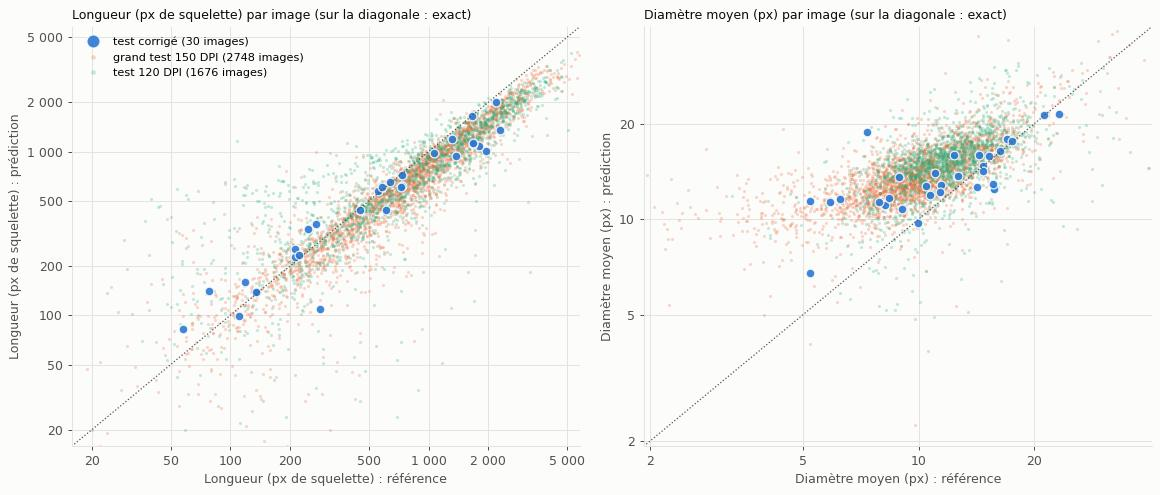

In [9]:
viz.save(viz.plot_traits({k: traits(t) for k, t in tables.items()}), 'test_longueurs_diametres.png')
pd.DataFrame({k: trait_scores(t) for k, t in tables.items()}).T.round(2)

**À retenir**
- **Longueur sous-estimée d'environ 20 %** sur les trois jeux (biais d'ensemble de -21 à -23 %), avec une erreur médiane de 18 à 26 % par image. Le modèle manque des fragments et coupe des racines.
- **Diamètre surestimé de 25 à 34 %** : les prédictions sont plus larges que les annotations, en partie parce que le modèle travaille à demi-résolution.
- **Les biais sont du même ordre sur les trois jeux**, capteur 120 DPI compris : une erreur stable se corrige mieux qu'une erreur aléatoire. Prochaine étape : élaguer les squelettes, mesurer en millimètres, et vérifier sur le val si un étalonnage réduit ces biais.

## 6. Vitesse

Sur 50 images du grand test, lues sur la clé : lecture et prétraitement, puis modèle seul, sur le processeur du portable (sans GPU).

In [10]:
pd.Series(timing(model, rows150, device)).to_frame('').T

,lecture et prétraitement (s / image),modèle (s / image),images par minute,processeur
,0.011074,0.066089,777.568309,"16 fils, cpu"


**À retenir** : environ 0,07 s par image sur un processeur de portable (16 fils), soit de l'ordre de 800 images par minute. Un tube entier (environ 750 images en 150 DPI) se traite en une minute, sans GPU. La lecture mesurée profite du cache disque : sur des images jamais lues, compter un peu plus.

## 7. Images du test corrigé

Au curseur, du plus bas Dice au plus haut, images sans racine à la fin (de la plus touchée à la moins touchée) : image seule, masque corrigé, prédiction.

In [11]:
preds = {it['name']: predict(model, it, device) for it in test_items}
viz.browse_predictions(test_items, preds, test, raw=True)

interactive(children=(IntSlider(value=0, continuous_update=False, description='Image', layout=Layout(width='80…

## 8. Images des grands tests

Même parcours sur le grand test 150 DPI puis sur le test 120 DPI : image seule, annotation PRMI comblée, prédiction. Chaque image est relue sur la clé au moment de l'afficher (clé branchée), la prédiction dans `data/processed/predictions/`. Les tests étant grands, le curseur va vite : les premières positions montrent les pires images avec racine, les dernières les images vides, des plus touchées aux moins touchées.

In [12]:
viz.browse_loaded(tables['grand test 150 DPI'], prediction_loader(NAME, rows150, 'test_150'))

interactive(children=(IntSlider(value=0, continuous_update=False, description='Image', layout=Layout(width='80…

In [13]:
viz.browse_loaded(tables['test 120 DPI'], prediction_loader(NAME, rows120, 'test_120'))

interactive(children=(IntSlider(value=0, continuous_update=False, description='Image', layout=Layout(width='80…